## Import

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

plt.rcParams["figure.figsize"] = (20,15)

In [2]:
hf = h5py.File('gammaray_lab4.h5', 'r')

In [3]:
hf.keys()

<KeysViewHDF5 ['data']>

In [4]:
data = np.array(hf.get('data'))

In [5]:
np.shape(data)
data[:,0]

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

In [6]:
hf.close()

## Lab 4

In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

As with most data, there are 'features.' Your lab instructor has helpfully incorporated the meta-data into your data file.

### Question 1

#### Part (a)

Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it.

In [7]:
data = pd.DataFrame(data).T

In [8]:
data.columns = ['Time (gps seconds)', 'Solar Phase (deg)', 'Earth longitude (deg)', 'Particle Counts']

In [9]:
time = data['Time (gps seconds)']
s_phase = data['Solar Phase (deg)']
e_long = data['Earth longitude (deg)']
counts = data['Particle Counts']

data['t_folded'] = time % (60*90)
t_folded = data['t_folded']

data

,Time (gps seconds),Solar Phase (deg),Earth longitude (deg),Particle Counts,t_folded
0,940680016.0,315.000000,45.000000,10.0,16.0
1,940680016.1,315.007112,45.006667,8.0,16.1
2,940680016.2,315.014225,45.013333,7.0,16.2
3,940680016.3,315.021337,45.020000,11.0,16.3
4,940680016.4,315.028449,45.026667,8.0,16.4
...,...,...,...,...,...
25919996,943272015.6,345.304884,44.973333,5.0,15.6
25919997,943272015.7,345.311996,44.980000,9.0,15.7
25919998,943272015.8,345.319109,44.986667,8.0,15.8
25919999,943272015.9,345.326221,44.993333,11.0,15.9


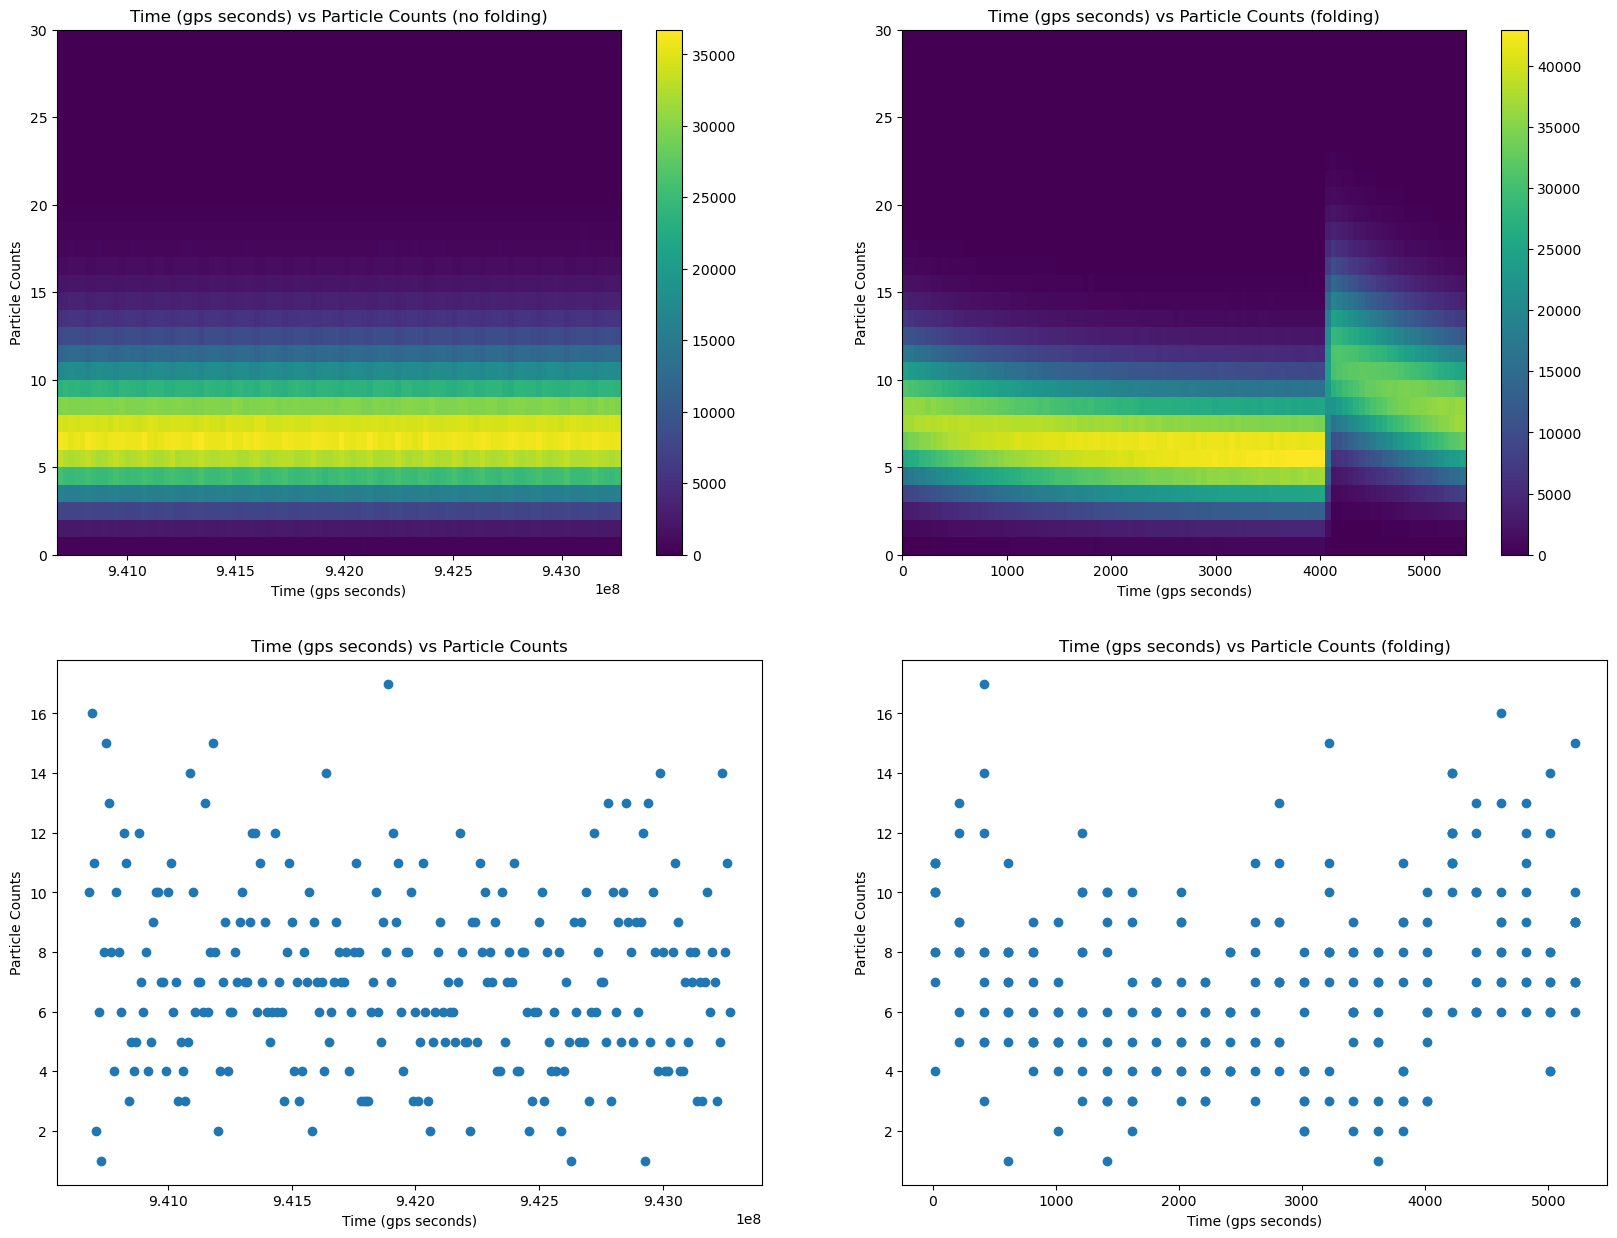

In [10]:
#Time vs Particle Counts

fig, ax = plt.subplot_mosaic(
    """
    AB
    CD
    """
)

im1 = ax['A'].hist2d(time, counts, bins = (100,30))
fig.colorbar(im1[3], ax = ax['A'])
ax['A'].set_xlabel('Time (gps seconds)')
ax['A'].set_ylabel('Particle Counts')
ax['A'].set_title('Time (gps seconds) vs Particle Counts (no folding)')

im2 = ax['B'].hist2d(t_folded, counts, bins = (100,30))
fig.colorbar(im2[3], ax = ax['B'])
ax['B'].set_xlabel('Time (gps seconds)')
ax['B'].set_ylabel('Particle Counts')
ax['B'].set_title('Time (gps seconds) vs Particle Counts (folding)')

ax['C'].scatter(time[::100000], counts[::100000])
ax['C'].set_xlabel('Time (gps seconds)')
ax['C'].set_ylabel('Particle Counts')
ax['C'].set_title('Time (gps seconds) vs Particle Counts')

ax['D'].scatter(t_folded[::100000], counts[::100000])
ax['D'].set_xlabel('Time (gps seconds)')
ax['D'].set_ylabel('Particle Counts')
ax['D'].set_title('Time (gps seconds) vs Particle Counts (folding)')

plt.show()

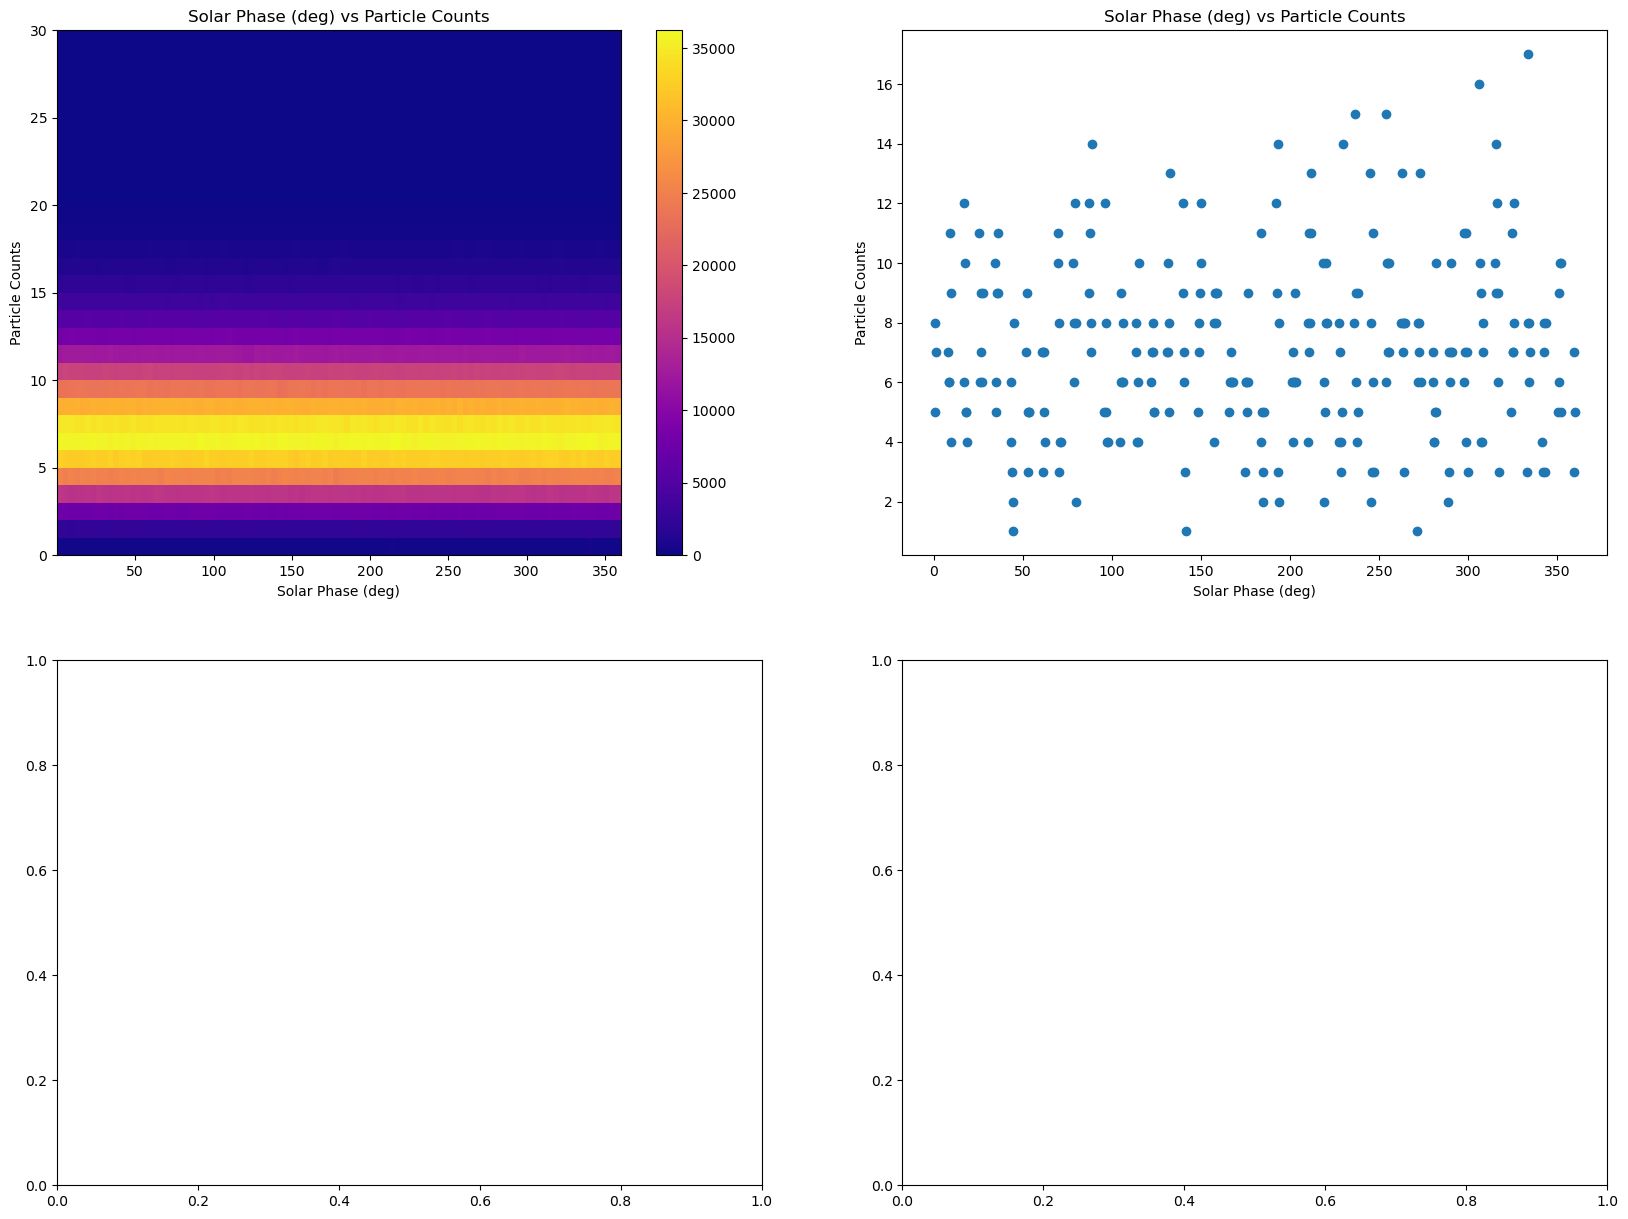

In [11]:
#Solar Phase versus Particle Counts

fig, ax = plt.subplot_mosaic(
    """
    AC
    BD
    """
)

im3 = ax['A'].hist2d(s_phase, counts, bins = (100,30), cmap = 'plasma')
fig.colorbar(im3[3], ax = ax['A'])
ax['A'].set_xlabel('Solar Phase (deg)')
ax['A'].set_ylabel('Particle Counts')
ax['A'].set_title('Solar Phase (deg) vs Particle Counts')

ax['C'].scatter(s_phase[::100000], counts[::100000])
ax['C'].set_xlabel('Solar Phase (deg)')
ax['C'].set_ylabel('Particle Counts')
ax['C'].set_title('Solar Phase (deg) vs Particle Counts')

plt.show()

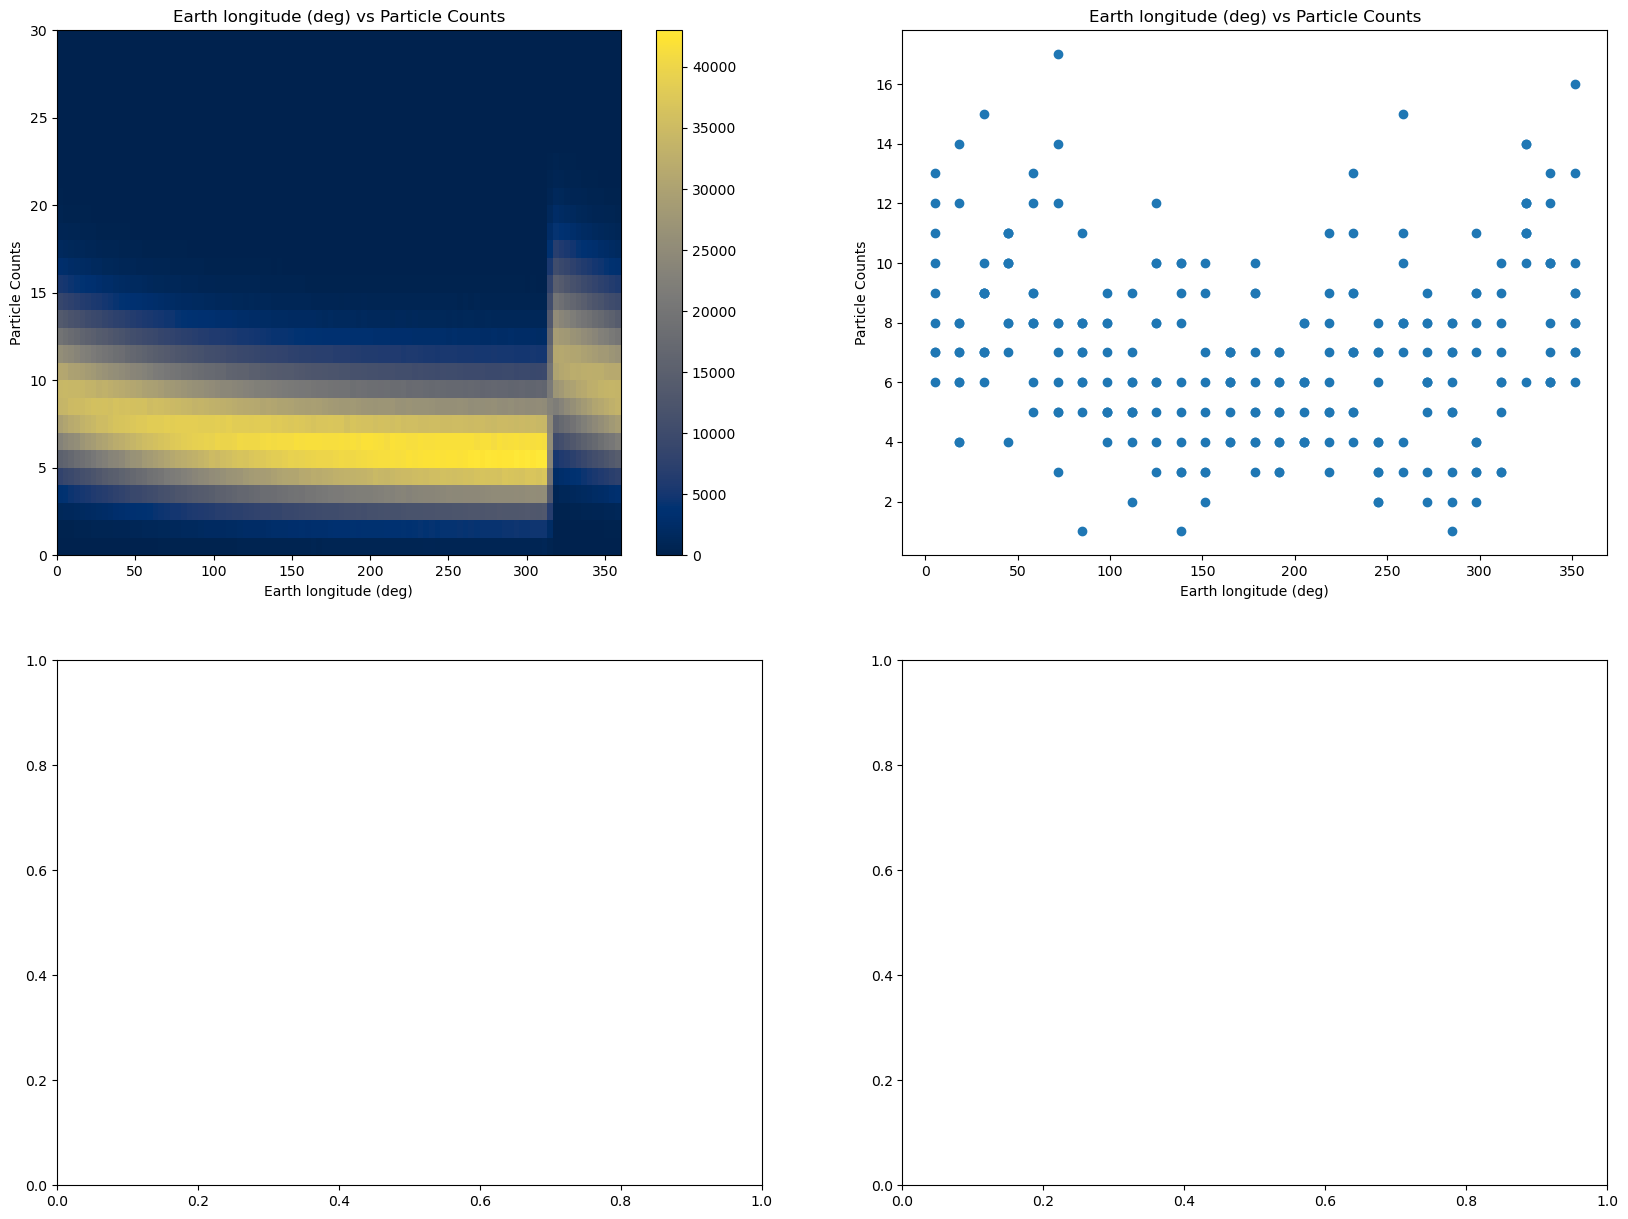

In [12]:
#Earth Longitude vs Particle Counts

fig, ax = plt.subplot_mosaic(
    """
    AC
    BD
    """
)

im4 = ax['A'].hist2d(e_long, counts, bins = (100,30), cmap = 'cividis')
fig.colorbar(im4[3], ax = ax['A'])
ax['A'].set_xlabel('Earth longitude (deg)')
ax['A'].set_ylabel('Particle Counts')
ax['A'].set_title('Earth longitude (deg) vs Particle Counts')

ax['C'].scatter(e_long[::100000], counts[::100000])
ax['C'].set_xlabel('Earth longitude (deg)')
ax['C'].set_ylabel('Particle Counts')
ax['C'].set_title('Earth longitude (deg) vs Particle Counts')

plt.show()

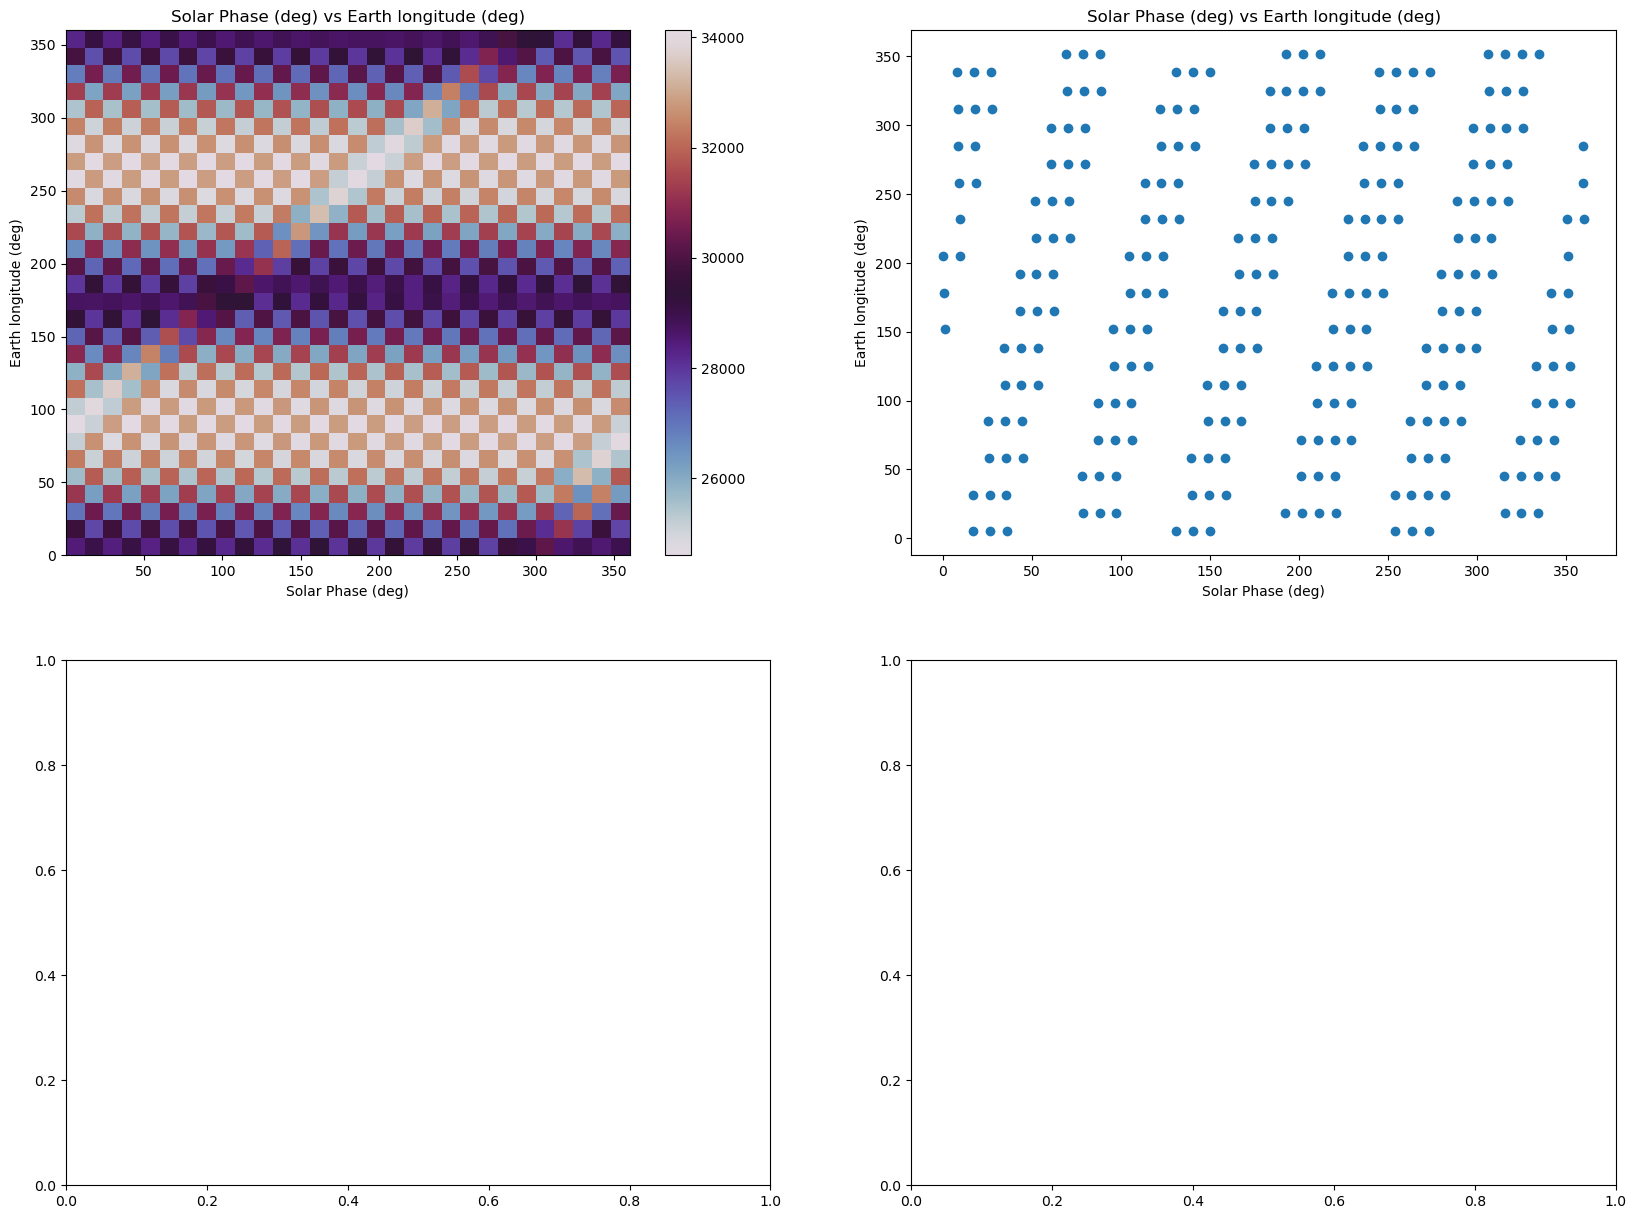

In [13]:
#Solar phase vs Earth longtitude. Not important, but pretty

fig, ax = plt.subplot_mosaic(
    """
    AC
    BD
    """
)

im5 = ax['A'].hist2d(s_phase, e_long, bins = 30, cmap = 'twilight')
fig.colorbar(im5[3], ax = ax['A'])
ax['A'].set_xlabel('Solar Phase (deg)')
ax['A'].set_ylabel('Earth longitude (deg)')
ax['A'].set_title('Solar Phase (deg) vs Earth longitude (deg)')

ax['C'].scatter(s_phase[::100000], e_long[::100000])
ax['C'].set_xlabel('Solar Phase (deg)')
ax['C'].set_ylabel('Earth longitude (deg)')
ax['C'].set_title('Solar Phase (deg) vs Earth longitude (deg)')

plt.show()

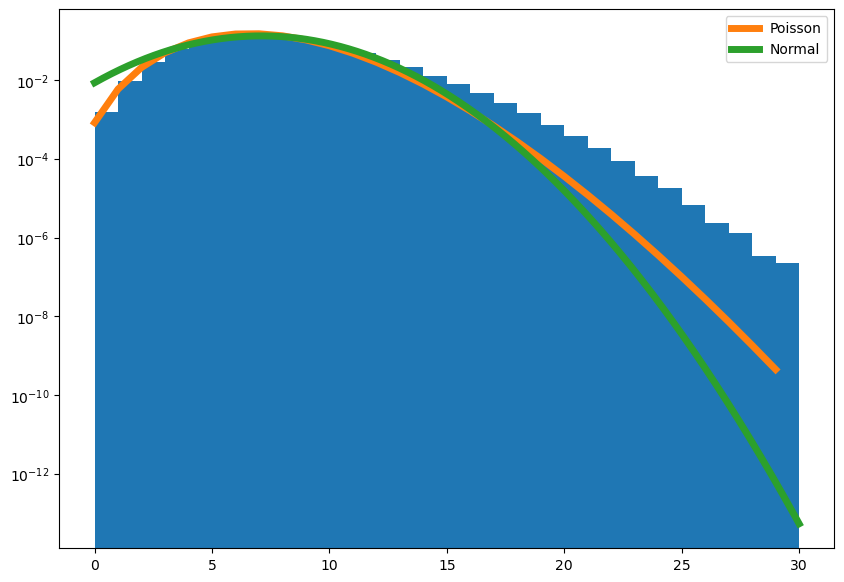

In [14]:
#Histogram of Particle Counts with a Poisson and Normal Distribution plotted over it

avg_count = np.mean(counts) 
sd_count = np.std(counts)

plt.figure(figsize=(10, 7))
plt.hist(counts, bins = 30, density = True)
p_range = np.arange(0,30)
plt.plot(p_range, stats.poisson.pmf(p_range, avg_count), linewidth = 5, label = 'Poisson')
n_range = np.linspace(0, 30, 1000)
plt.plot(n_range, stats.norm.pdf(n_range, avg_count, sd_count), linewidth = 5, label = 'Normal')
plt.yscale('log')
plt.legend()
plt.show()

#### Part (b)

Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

**Time vs Counts:** Without folding, the count rate remains relatively constant around 6 gamma particle counts every 100 milliseconds regardless of the time it was taken at. After folding, there is a small, exponential looking decrease from 8 or 9 counts to 6 or 7 counts every 100 milliseconds. At around 4000 seconds in the satellites orbit, there is a large jump in the detection rate to around 12 counts every 100 milliseconds followed by an exponential decrease to where it continues seamlessly as it restarts it's orbit. The scatter plot also reveals that potentially cyclic relation between time and counts (folded). For both folding and not folding, there is a steady decrease in the number of times counts of gamma particles per 100 milliseconds were detected on either side of the max line (yellow).

**Solar Phase vs Counts:** Same as Time vs Counts (not folded)

**Earth Longitude vs Counts**: Same as Time vs Counts (folded)

**Counts vs Poisson Distribution**: The counts follow a poisson distribution, however, our data is giving us more instances of a higher number of counts than expected based on the poisson distribution background. It does not follow a normal distibution.


**Build a background pdf**: Take slices of histogram of particle counts every ~1000 seconds. Plot a poisson distribution with the lambda parameter of the mean of the particle counts over those slices to check how good the model is.

### Question 2
The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

As seen in the first set of plots, specifically time vs counts (folded), there is a sharp jump in the number of particles detected. The background follows a Poisson distribution where the lambda parameters decreases slowly until it sharply jumps around 4100s, or around when the spacecraft is above 310 degrees (earth longitude) below decreasing again.

The count rate is around 7-8 counts per 100 milliseconds decreasing to 5-6 counts per 100 milliseconds before sharply jumping to around 10-12 counts per 100 milliseconds (around 4100s). It decreases quickly to 7-8 counts where it continues this cycle.

So, at a certain time in the orbit/over a certain earth longtitude, the background count changes dramatically.

### Question 3
Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?

In [15]:
#Subsets of data
data1 = data[(t_folded >= 0) & (t_folded < 1000)]
data2 = data[(t_folded >= 1000) & (t_folded < 2000)]
data3 = data[(t_folded >= 2000) & (t_folded < 3000)]
data4 = data[(t_folded >= 3000) & (t_folded < 4000)]
data5 = data[(t_folded >= 4000) & (t_folded < 5000)]
data6 = data[(t_folded >= 5000) & (t_folded < 6000)]

In [16]:
#Creating mean for each subset
avgs = []

for i in data1, data2, data3, data4, data5, data6:
    means = np.mean(i['Particle Counts'])
    avgs.append(means)

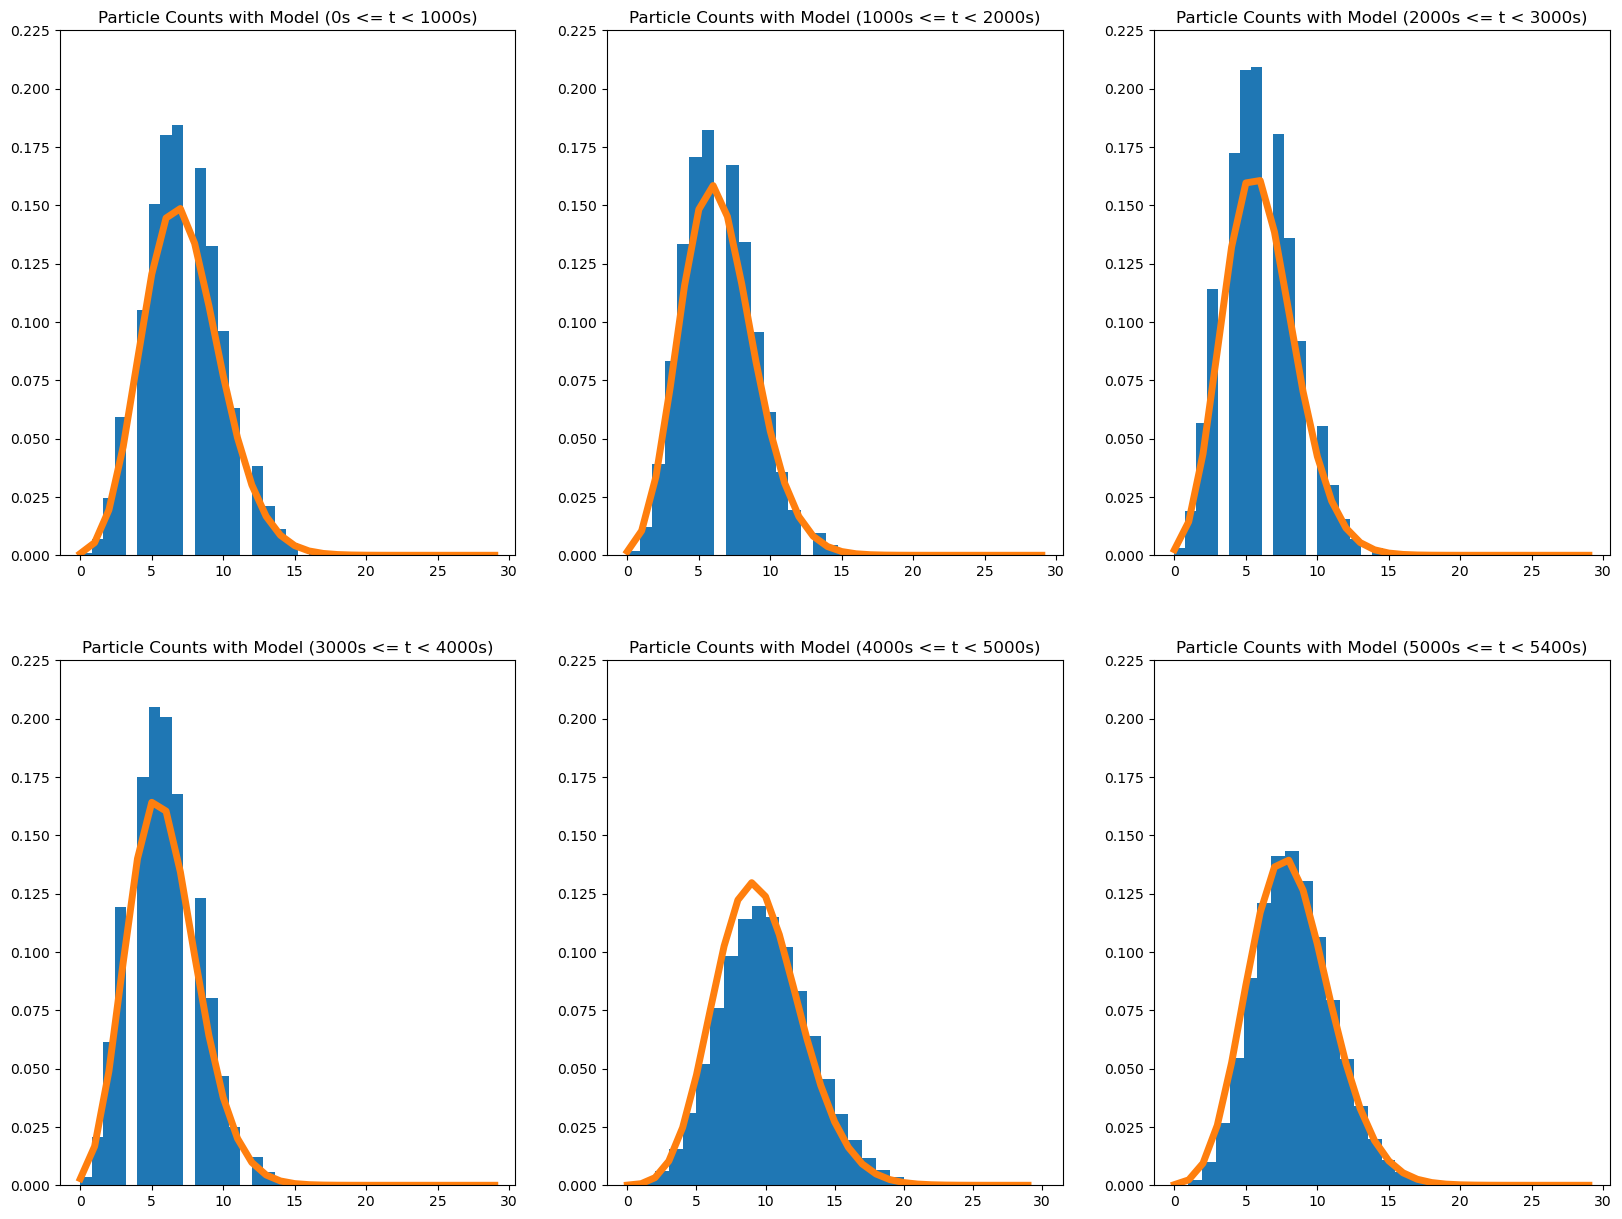

In [17]:
#Histogram of Particle Counts with a Poisson Distribution over top

fig, ax = plt.subplot_mosaic(
    """
    ABC
    DEF
    """
)

x_range = np.arange(0,30)

for axs in ax.values():
    axs.set_ylim(0, .225)

ax['A'].hist(data1['Particle Counts'], bins = 30, density = True)
ax['A'].plot(x_range, stats.poisson.pmf(x_range, avgs[0]), linewidth = 5)
ax['A'].set_title("Particle Counts with Model (0s <= t < 1000s)")
ax['B'].hist(data2['Particle Counts'], bins = 30, density = True)
ax['B'].plot(x_range, stats.poisson.pmf(x_range, avgs[1]), linewidth = 5)
ax['B'].set_title("Particle Counts with Model (1000s <= t < 2000s)")
ax['C'].hist(data3['Particle Counts'], bins = 30, density = True)
ax['C'].plot(x_range, stats.poisson.pmf(x_range, avgs[2]), linewidth = 5)
ax['C'].set_title("Particle Counts with Model (2000s <= t < 3000s)")
ax['D'].hist(data4['Particle Counts'], bins = 30, density = True)
ax['D'].plot(x_range, stats.poisson.pmf(x_range, avgs[3]), linewidth = 5)
ax['D'].set_title("Particle Counts with Model (3000s <= t < 4000s)")
ax['E'].hist(data5['Particle Counts'], bins = 30, density = True)
ax['E'].plot(x_range, stats.poisson.pmf(x_range, avgs[4]), linewidth = 5)
ax['E'].set_title("Particle Counts with Model (4000s <= t < 5000s)")
ax['F'].hist(data6['Particle Counts'], bins = 30, density = True)
ax['F'].plot(x_range, stats.poisson.pmf(x_range, avgs[5]), linewidth = 5)
ax['F'].set_title("Particle Counts with Model (5000s <= t < 5400s)")
plt.show()

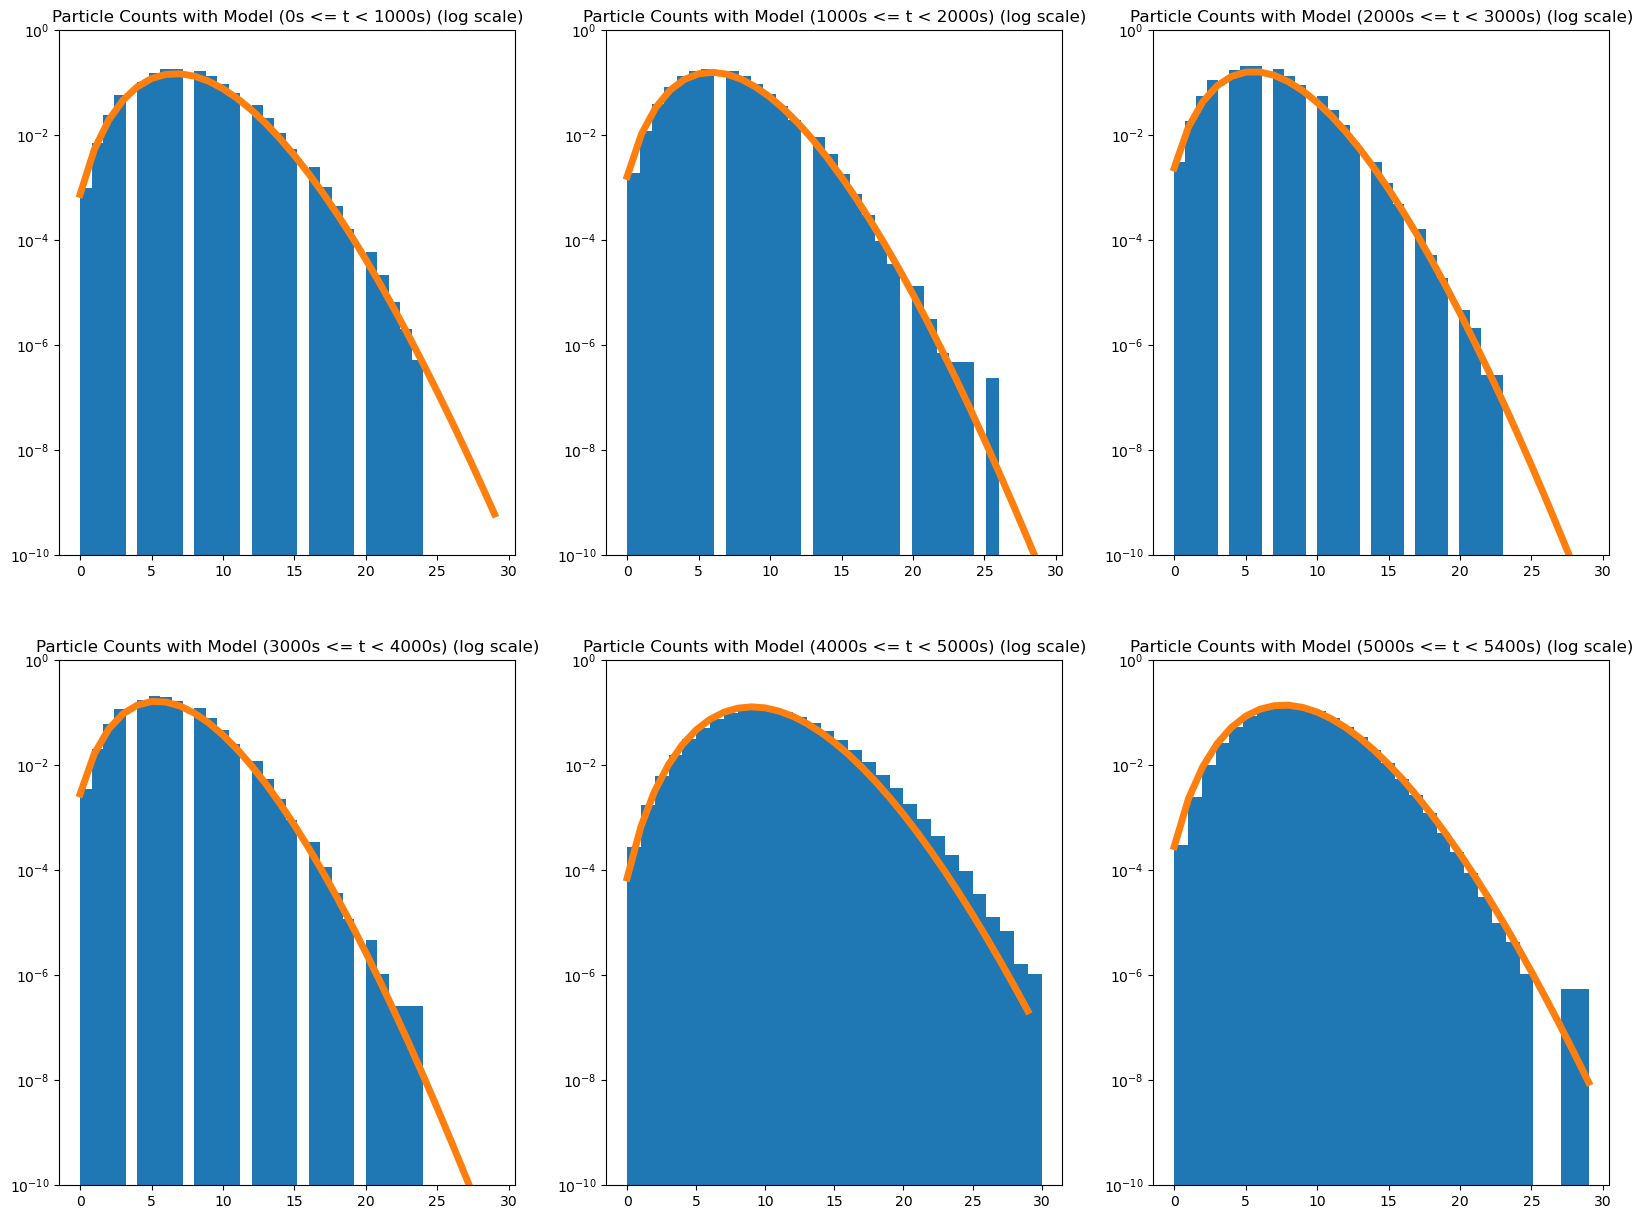

In [18]:
#Histogram of Particle Counts with a Poisson Distribution over top (log scale)

fig, ax = plt.subplot_mosaic(
    """
    ABC
    DEF
    """
)

x_range = np.arange(0,30)

for axs in ax.values():
    axs.set_yscale("log")
    axs.set_ylim(10**(-10), 10**(0))

ax['A'].hist(data1['Particle Counts'], bins = 30, density = True)
ax['A'].plot(x_range, stats.poisson.pmf(x_range, avgs[0]), linewidth = 5)
ax['A'].set_title("Particle Counts with Model (0s <= t < 1000s) (log scale)")
ax['B'].hist(data2['Particle Counts'], bins = 30, density = True)
ax['B'].plot(x_range, stats.poisson.pmf(x_range, avgs[1]), linewidth = 5)
ax['B'].set_title("Particle Counts with Model (1000s <= t < 2000s) (log scale)")
ax['C'].hist(data3['Particle Counts'], bins = 30, density = True)
ax['C'].plot(x_range, stats.poisson.pmf(x_range, avgs[2]), linewidth = 5)
ax['C'].set_title("Particle Counts with Model (2000s <= t < 3000s) (log scale)")
ax['D'].hist(data4['Particle Counts'], bins = 30, density = True)
ax['D'].plot(x_range, stats.poisson.pmf(x_range, avgs[3]), linewidth = 5)
ax['D'].set_title("Particle Counts with Model (3000s <= t < 4000s) (log scale)")
ax['E'].hist(data5['Particle Counts'], bins = 30, density = True)
ax['E'].plot(x_range, stats.poisson.pmf(x_range, avgs[4]), linewidth = 5)
ax['E'].set_title("Particle Counts with Model (4000s <= t < 5000s) (log scale)")
ax['F'].hist(data6['Particle Counts'], bins = 30, density = True)
ax['F'].plot(x_range, stats.poisson.pmf(x_range, avgs[5]), linewidth = 5)
ax['F'].set_title("Particle Counts with Model (5000s <= t < 5400s) (log scale)")
plt.show()

I would say that my model is pretty good! Plotting the proposed model (orange) over the time slices of the data in the ylog-scale shows that it's relatively good as the orange line overlays quite nicely with the data. The fifth slice (bottom middle) is slightly off. I believe that's because of the anomaly we are observing starting slightly after 4000s (around 4100s?).

### Question 4
Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?

In [19]:
#Sds for Poisson (sqrt(lambda))
stds_4 = []
for i in np.arange(0, 6):
    p_pmf = stats.poisson.pmf(x_range, avgs[i])
    std = np.sqrt(avgs[i])
    stds_4.append(std)

#5 sigma for Poisson
sigma5 = []
for i in np.arange(0, 6):
    sigma5_a = avgs[i] + 5*stds_4[i]
    sigma5.append(sigma5_a)

In [20]:
print(
    f"""For 0 =< t < 1000 seconds, 5 sigma is {sigma5[0]:.4f}.
For 1000 =< t < 2000 seconds, 5 sigma is {sigma5[1]:.4f}.
For 2000 =< t < 3000 seconds, 5 sigma is {sigma5[2]:.4f}.
For 3000 =< t < 4000 seconds, 5 sigma is {sigma5[3]:.4f}.
For 4000 =< t < 5000 seconds, 5 sigma is {sigma5[4]:.4f}.
For 5000 =< t < 5400 seconds, 5 sigma is {sigma5[5]:.4f}.
""")

For 0 =< t < 1000 seconds, 5 sigma is 20.6103.
For 1000 =< t < 2000 seconds, 5 sigma is 19.0761.
For 2000 =< t < 3000 seconds, 5 sigma is 18.3252.
For 3000 =< t < 4000 seconds, 5 sigma is 17.9693.
For 4000 =< t < 5000 seconds, 5 sigma is 24.9934.
For 5000 =< t < 5400 seconds, 5 sigma is 22.4630.



### Question 5
While this is simulated data, it is based on a real effect seen by low Earth orbit satellites. Can you identify the cause of the variable background and propose a physical model?

South Atlantic Anomaly. The change happens at earth longitude of around ~310-330 degrees (aka 50W - 30W) which is almost exactly where the South Atlantic Anomaly is (Earth's magnetic field is quite weak there).